<a href="https://colab.research.google.com/github/IchiroBanskota/Bot-Detection/blob/master/Bot_Detection-2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Compare models

In [ ]:
import pandas as pd

from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    cross_validate
)

from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (
    RandomForestClassifier,
    HistGradientBoostingClassifier
)
from sklearn.neural_network import MLPClassifier

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

In [ ]:
import kagglehub
import pandas as pd
import os

# Download or locate the cached dataset
path = kagglehub.dataset_download(
    "danieltreiman/twitter-human-bots-dataset"
)

print("Dataset location:", path)
print("Files:", os.listdir(path))

# Load dataset
df = pd.read_csv(
    os.path.join(path, "twitter_human_bots_dataset.csv")
)

# Display first 5 rows
display(df.head())

print("Dataset shape:", df.shape)

# Remove columns not used in your baseline
columns_to_drop = [
    "Unnamed: 0",
    "created_at",
    "description",
    "id",
    "lang",
    "location",
    "profile_background_image_url",
    "profile_image_url",
    "screen_name",
    "profile_image_path",
    "profile_background_image_path",
    "split"
]

df = df.drop(columns=columns_to_drop)

# Remove missing values and duplicates
df = df.dropna()
df = df.drop_duplicates()

# Convert boolean features to integers
boolean_columns = [
    "default_profile",
    "default_profile_image",
    "geo_enabled",
    "verified"
]

df[boolean_columns] = df[boolean_columns].astype(int)

# Convert labels
df["account_type"] = (
    df["account_type"] == "bot"
).astype(int)

# Features and target
X = df.drop(columns=["account_type"])
y = df["account_type"]

print("Features:", X.columns.tolist())
print("Dataset shape:", X.shape)

100%|██████████| 48.9M/48.9M [00:00<00:00, 155MB/s]

Extracting files...


Dataset location: /root/.cache/kagglehub/datasets/danieltreiman/twitter-human-bots-dataset/versions/4
Files: ['profile_background_images', 'profile_images', 'twitter_human_bots_dataset.csv']


,Unnamed: 0,created_at,default_profile,default_profile_image,description,favourites_count,followers_count,friends_count,geo_enabled,id,...,profile_image_url,screen_name,statuses_count,verified,average_tweets_per_day,account_age_days,account_type,profile_image_path,profile_background_image_path,split
0,0,2009-07-04 22:41:51,False,False,NaN,5007,102,168,False,53779179,...,https://pbs.twimg.com/profile_images/128969130...,paty_castroo,3974,False,0.978,4063,bot,NaN,NaN,0
1,1,2010-01-17 22:54:19,False,False,Television producer. Emmy Award winner. Disney...,1038,60,128,False,105916557,...,https://pbs.twimg.com/profile_images/632916759...,CBirckner,259,False,0.067,3866,human,profile_images/4691ae58668d932bb7e7af22141aecf...,profile_images/4691ae58668d932bb7e7af22141aecf...,0
2,2,2012-03-01 06:05:32,False,False,NaN,2257,599,449,True,509788597,...,https://pbs.twimg.com/profile_images/128853844...,amf_jay,13627,False,4.406,3093,human,NaN,NaN,0
3,3,2009-09-01 04:52:30,False,False,NaN,6407,116,334,True,70601327,...,https://pbs.twimg.com/profile_images/977012905...,SaraCavolo,4432,False,1.107,4005,human,profile_images/d1da9220e4aa376dff03b6f12765171...,profile_images/d1da9220e4aa376dff03b6f12765171...,0
4,4,2010-01-27 17:17:23,False,False,Productor de Televisión - Embajador de @Tienda...,20866,74448,18,True,108999927,...,https://pbs.twimg.com/profile_images/668449819...,DavidHenaoModel,15870,True,4.116,3856,human,profile_images/c65bf625b066ef5f29e14cfcf1ee91f...,profile_images/c65bf625b066ef5f29e14cfcf1ee91f...,0


Dataset shape: (37438, 23)
Features: ['default_profile', 'default_profile_image', 'favourites_count', 'followers_count', 'friends_count', 'geo_enabled', 'statuses_count', 'verified', 'average_tweets_per_day', 'account_age_days']
Dataset shape: (37404, 10)


In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [ ]:
models = {
    "Logistic Regression": make_pipeline(
        StandardScaler(),
        LogisticRegression(max_iter=2000)
    ),

    "Decision Tree": DecisionTreeClassifier(
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        random_state=42
    ),

    "Gradient Boosting": HistGradientBoostingClassifier(
        random_state=42
    ),

    "Neural Network (MLP)": make_pipeline(
        StandardScaler(),
        MLPClassifier(
            hidden_layer_sizes=(64, 32),
            max_iter=500,
            random_state=42
        )
    )
}

In [ ]:
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

results = []

for name, model in models.items():

    scores = cross_validate(
        model,
        X_train,
        y_train,
        cv=cv,
        scoring={
            "accuracy": "accuracy",
            "precision": "precision",
            "recall": "recall",
            "f1": "f1"
        }
    )

    results.append({
        "Model": name,
        "Accuracy": scores["test_accuracy"].mean(),
        "Precision": scores["test_precision"].mean(),
        "Bot Recall": scores["test_recall"].mean(),
        "Bot F1": scores["test_f1"].mean()
    })

results_df = pd.DataFrame(results)

display(
    results_df.sort_values(
        by="Bot F1",
        ascending=False
    )
)

,Model,Accuracy,Precision,Bot Recall,Bot F1
3,Gradient Boosting,0.880059,0.857996,0.764848,0.808709
2,Random Forest,0.880326,0.862998,0.759605,0.807967
1,Decision Tree,0.826588,0.734959,0.745790,0.740320
4,Neural Network (MLP),0.830465,0.772508,0.694862,0.730439
0,Logistic Regression,0.757745,0.654006,0.571443,0.609916


In [ ]:
# Select best model using CV F1
best_name = results_df.loc[
    results_df["Bot F1"].idxmax(),
    "Model"
]

best_model = models[best_name]

# Train on the entire training set
best_model.fit(X_train, y_train)

# Evaluate on untouched test data
y_pred = best_model.predict(X_test)

print("Best model:", best_name)
print(classification_report(y_test, y_pred))
print("Confusion matrix:")
print(confusion_matrix(y_test, y_pred))

display(
    results_df.sort_values(
        by="Bot F1",
        ascending=False
    ).round(4)
)

Best model: Gradient Boosting
              precision    recall  f1-score   support

           0       0.89      0.93      0.91      5002
           1       0.84      0.76      0.80      2479

    accuracy                           0.87      7481
   macro avg       0.87      0.85      0.85      7481
weighted avg       0.87      0.87      0.87      7481

Confusion matrix:
[[4651  351]
 [ 590 1889]]


,Model,Accuracy,Precision,Bot Recall,Bot F1
3,Gradient Boosting,0.8801,0.8580,0.7648,0.8087
2,Random Forest,0.8803,0.8630,0.7596,0.8080
1,Decision Tree,0.8266,0.7350,0.7458,0.7403
4,Neural Network (MLP),0.8305,0.7725,0.6949,0.7304
0,Logistic Regression,0.7577,0.6540,0.5714,0.6099


## SHAP

In [ ]:
# TWITTER BOT DETECTION — SHAP EXPLAINABILITY

%pip -q install kagglehub shap

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import kagglehub
import shap

from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)


In [ ]:
# Load dataset

path = kagglehub.dataset_download(
    "danieltreiman/twitter-human-bots-dataset"
)

df = pd.read_csv(
    os.path.join(path, "twitter_human_bots_dataset.csv")
)

print("Original dataset shape:", df.shape)

df.head()

Using Colab cache for faster access to the 'twitter-human-bots-dataset' dataset.
Original dataset shape: (37438, 23)


,Unnamed: 0,created_at,default_profile,default_profile_image,description,favourites_count,followers_count,friends_count,geo_enabled,id,...,profile_image_url,screen_name,statuses_count,verified,average_tweets_per_day,account_age_days,account_type,profile_image_path,profile_background_image_path,split
0,0,2009-07-04 22:41:51,False,False,NaN,5007,102,168,False,53779179,...,https://pbs.twimg.com/profile_images/128969130...,paty_castroo,3974,False,0.978,4063,bot,NaN,NaN,0
1,1,2010-01-17 22:54:19,False,False,Television producer. Emmy Award winner. Disney...,1038,60,128,False,105916557,...,https://pbs.twimg.com/profile_images/632916759...,CBirckner,259,False,0.067,3866,human,profile_images/4691ae58668d932bb7e7af22141aecf...,profile_images/4691ae58668d932bb7e7af22141aecf...,0
2,2,2012-03-01 06:05:32,False,False,NaN,2257,599,449,True,509788597,...,https://pbs.twimg.com/profile_images/128853844...,amf_jay,13627,False,4.406,3093,human,NaN,NaN,0
3,3,2009-09-01 04:52:30,False,False,NaN,6407,116,334,True,70601327,...,https://pbs.twimg.com/profile_images/977012905...,SaraCavolo,4432,False,1.107,4005,human,profile_images/d1da9220e4aa376dff03b6f12765171...,profile_images/d1da9220e4aa376dff03b6f12765171...,0
4,4,2010-01-27 17:17:23,False,False,Productor de Televisión - Embajador de @Tienda...,20866,74448,18,True,108999927,...,https://pbs.twimg.com/profile_images/668449819...,DavidHenaoModel,15870,True,4.116,3856,human,profile_images/c65bf625b066ef5f29e14cfcf1ee91f...,profile_images/c65bf625b066ef5f29e14cfcf1ee91f...,0


In [ ]:
# Clean data

df["account_type"] = (
    df["account_type"]
    .astype(str)
    .str.strip()
    .str.lower()
    .map({"human": 0, "bot": 1})
)

df = df.dropna(subset=["account_type", "split"])
df = df.drop_duplicates(subset=["id"]).copy()

df["account_type"] = df["account_type"].astype(int)
df["split"] = pd.to_numeric(df["split"], errors="coerce")

df = df[df["split"].isin([0, 1, 2])].reset_index(drop=True)

print("Cleaned dataset shape:", df.shape)

print("\nAccount type distribution:")
print(df["account_type"].value_counts())

print("\nDataset split distribution:")
print(df["split"].value_counts())

Cleaned dataset shape: (37438, 23)

Account type distribution:
account_type
0    25013
1    12425
Name: count, dtype: int64

Dataset split distribution:
split
0    29950
2     3745
1     3743
Name: count, dtype: int64


In [ ]:
# Select original features

original_features = [
    "default_profile",
    "default_profile_image",
    "favourites_count",
    "followers_count",
    "friends_count",
    "geo_enabled",
    "statuses_count",
    "verified",
    "average_tweets_per_day",
    "account_age_days"
]

for col in original_features:
    df[col] = pd.to_numeric(df[col], errors="coerce")

print("Original features selected:", len(original_features))

Original features selected: 10


In [ ]:
# Feature engineering

# Follower-to-following ratio
df["follower_following_ratio"] = (
    df["followers_count"] / (df["friends_count"] + 1)
)

# Tweets per follower
df["tweets_per_follower"] = (
    df["statuses_count"] / (df["followers_count"] + 1)
)

# Likes per tweet
df["likes_per_tweet"] = (
    df["favourites_count"] / (df["statuses_count"] + 1)
)

# Biography features
df["bio_length"] = (
    df["description"].fillna("").astype(str).str.len()
)

df["has_bio"] = (
    df["description"]
    .fillna("")
    .astype(str)
    .str.strip()
    .ne("")
    .astype(int)
)

# Username features
df["username_length"] = (
    df["screen_name"].fillna("").astype(str).str.len()
)

df["username_digit_count"] = (
    df["screen_name"]
    .fillna("")
    .astype(str)
    .apply(lambda s: sum(c.isdigit() for c in s))
)

df["username_digit_ratio"] = (
    df["username_digit_count"]
    / df["username_length"].clip(lower=1)
)

# Log-transformed features
df["log_followers"] = np.log1p(
    df["followers_count"].clip(lower=0)
)

df["log_statuses"] = np.log1p(
    df["statuses_count"].clip(lower=0)
)

engineered_features = [
    "follower_following_ratio",
    "tweets_per_follower",
    "likes_per_tweet",
    "bio_length",
    "has_bio",
    "username_length",
    "username_digit_count",
    "username_digit_ratio",
    "log_followers",
    "log_statuses"
]

print("Engineered features created:", len(engineered_features))

Engineered features created: 10


In [ ]:
# Prepare feature matrix

features = original_features + engineered_features

X = df[features].replace(
    [np.inf, -np.inf], np.nan
)

y = df["account_type"]

print("Number of original features:", len(original_features))
print("Number of engineered features:", len(engineered_features))
print("Total number of features:", len(features))

print("\nFeature matrix shape:", X.shape)
print("Target variable shape:", y.shape)

Number of original features: 10
Number of engineered features: 10
Total number of features: 20

Feature matrix shape: (37438, 20)
Target variable shape: (37438,)


In [ ]:
# Use predefined dataset splits

train_mask = df["split"] == 0
valid_mask = df["split"] == 1
test_mask = df["split"] == 2

X_train = X.loc[train_mask]
y_train = y.loc[train_mask]

X_valid = X.loc[valid_mask]
y_valid = y.loc[valid_mask]

X_test = X.loc[test_mask]
y_test = y.loc[test_mask]

print("Training accounts:", len(X_train))
print("Validation accounts:", len(X_valid))
print("Testing accounts:", len(X_test))

Training accounts: 29950
Validation accounts: 3743
Testing accounts: 3745


In [ ]:
# Train Random Forest model

model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("model", RandomForestClassifier(
        n_estimators=100,
        random_state=42,
        n_jobs=1
    ))
])

model.fit(X_train, y_train)

print("Random Forest trained successfully.")

Random Forest trained successfully.


In [ ]:
# Evaluate validation performance

y_pred = model.predict(X_valid)

print("\n========== VALIDATION RESULTS ==========")

print("Accuracy:", round(
    accuracy_score(y_valid, y_pred), 4
))

print("Bot Precision:", round(
    precision_score(y_valid, y_pred, zero_division=0), 4
))

print("Bot Recall:", round(
    recall_score(y_valid, y_pred, zero_division=0), 4
))

print("Bot F1:", round(
    f1_score(y_valid, y_pred, zero_division=0), 4
))

print("\nClassification Report:")

print(classification_report(
    y_valid,
    y_pred,
    target_names=["Human", "Bot"],
    zero_division=0
))


========== VALIDATION RESULTS ==========
Accuracy: 0.883
Bot Precision: 0.8899
Bot Recall: 0.7466
Bot F1: 0.812

Classification Report:
              precision    recall  f1-score   support

       Human       0.88      0.95      0.92      2476
         Bot       0.89      0.75      0.81      1267

    accuracy                           0.88      3743
   macro avg       0.89      0.85      0.86      3743
weighted avg       0.88      0.88      0.88      3743



In [ ]:
# Prepare data for SHAP

# Sample validation accounts not seen during training
X_shap = X_valid.sample(
    n=min(300, len(X_valid)),
    random_state=42
)

# Extract trained imputer and Random Forest
imputer = model.named_steps["imputer"]
forest = model.named_steps["model"]

# Apply imputation
X_processed = pd.DataFrame(
    imputer.transform(X_shap),
    columns=features,
    index=X_shap.index
)

print("SHAP dataset shape:", X_processed.shape)
print("Preparing to compute SHAP values...")

SHAP dataset shape: (300, 20)
Preparing to compute SHAP values...


In [ ]:
# Compute SHAP values

explainer = shap.TreeExplainer(forest)

shap_values = explainer(X_processed)

# For a binary Random Forest, recent SHAP versions
# return one explanation per class.
# Class 1 = Bot.

if shap_values.values.ndim == 3:
    bot_shap = shap_values[:, :, 1]
else:
    bot_shap = shap_values

print("SHAP computation completed.")

SHAP computation completed.


SHAP BEESWARM PLOT


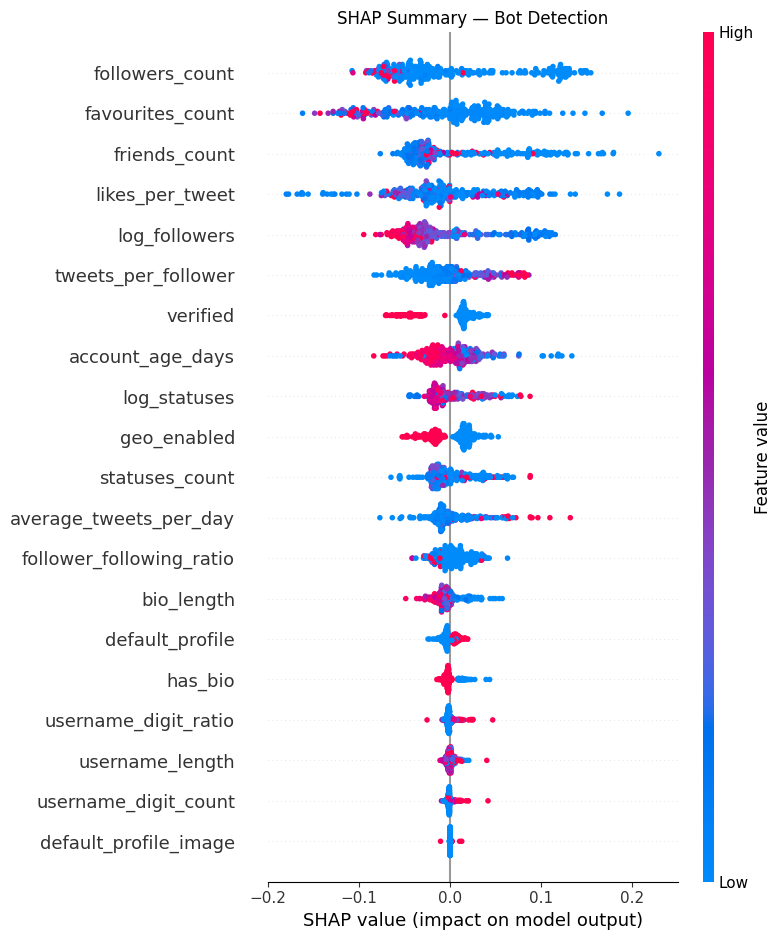

In [ ]:
# SHAP beeswarm plot

print("SHAP BEESWARM PLOT")

shap.plots.beeswarm(
    bot_shap,
    max_display=20,
    show=False
)

plt.title("SHAP Summary — Bot Detection")
plt.tight_layout()
plt.show()


SHAP WATERFALL PLOT
Actual class: 1
Predicted class: 1
Predicted bot probability: 1.0


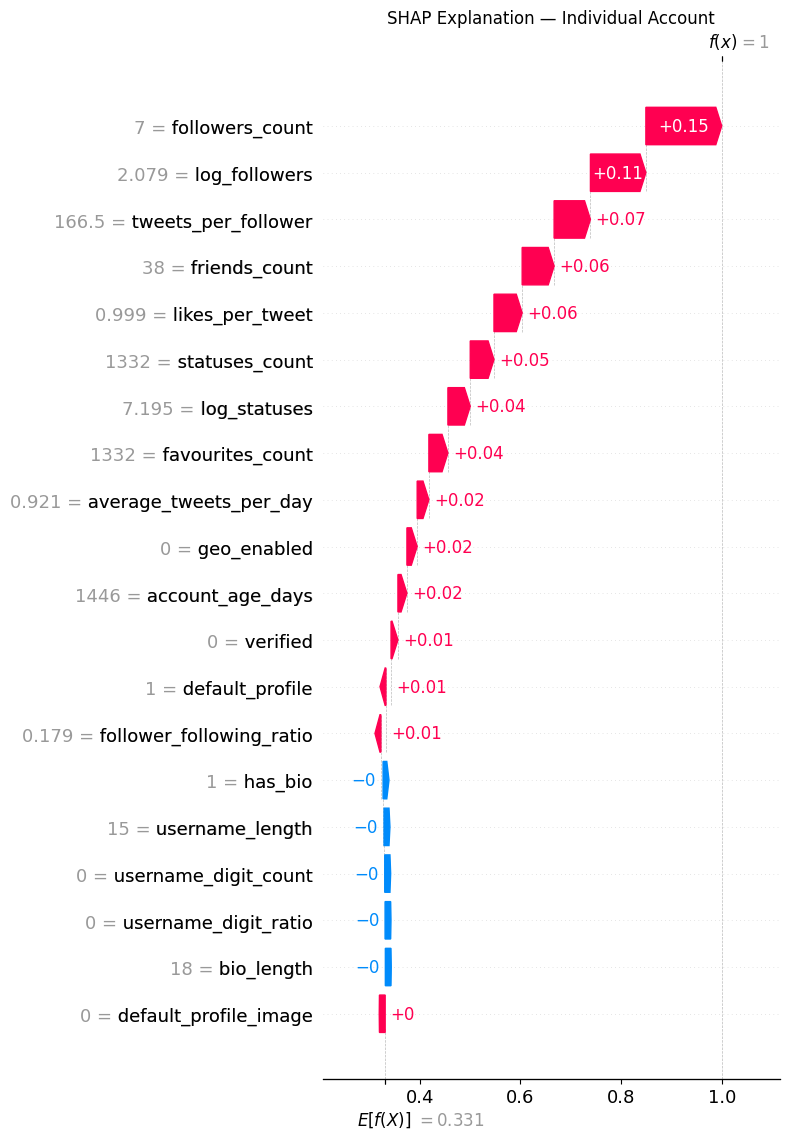

In [ ]:
# Explain an individual bot prediction

predictions = model.predict(X_shap)

# Prefer an account predicted as a bot
bot_indices = np.where(predictions == 1)[0]

if len(bot_indices) > 0:
    example_idx = int(bot_indices[0])
else:
    example_idx = 0

print("\nSHAP WATERFALL PLOT")

print(
    "Actual class:",
    int(y_valid.loc[X_shap.index[example_idx]])
)

print(
    "Predicted class:",
    int(predictions[example_idx])
)

print(
    "Predicted bot probability:",
    round(
        float(model.predict_proba(
            X_shap.iloc[[example_idx]]
        )[0, 1]),
        4
    )
)

shap.plots.waterfall(
    bot_shap[example_idx],
    max_display=20,
    show=False
)

plt.title("SHAP Explanation — Individual Account")
plt.tight_layout()
plt.show()

In [ ]:
# Save SHAP feature importance

importance = pd.DataFrame({
    "Feature": features,
    "Mean_Absolute_SHAP": np.abs(
        bot_shap.values
    ).mean(axis=0)
})

importance = importance.sort_values(
    "Mean_Absolute_SHAP",
    ascending=False
)

print("\n========== SHAP FEATURE RANKING ==========")

print(importance.to_string(index=False))

importance.to_csv(
    "shap_feature_importance.csv",
    index=False
)

print("\nSaved: shap_feature_importance.csv")

print("\nSHAP EXPLAINABILITY EXPERIMENT COMPLETE")


========== SHAP FEATURE RANKING ==========
                 Feature  Mean_Absolute_SHAP
         followers_count            0.058860
        favourites_count            0.050085
           friends_count            0.048056
         likes_per_tweet            0.044746
           log_followers            0.044279
     tweets_per_follower            0.027153
                verified            0.024838
        account_age_days            0.023950
            log_statuses            0.019850
             geo_enabled            0.019757
          statuses_count            0.018912
  average_tweets_per_day            0.018313
follower_following_ratio            0.013460
              bio_length            0.011056
         default_profile            0.005774
                 has_bio            0.005241
    username_digit_ratio            0.003284
         username_length            0.003065
    username_digit_count            0.002598
   default_profile_image            0.000288

Saved: sha

#DESCRIPTION AND USERNAME ENTROPY

In [ ]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from collections import Counter

def calculate_entropy(text):

    if pd.isna(text):
        return 0.0

    text = str(text).lower().strip()

    if len(text) == 0:
        return 0.0

    character_counts = Counter(text)

    probabilities = (
        np.array(list(character_counts.values()))
        / len(text)
    )

    entropy = -np.sum(
        probabilities * np.log2(probabilities)
    )

    return float(entropy)


# Create entropy features
df["description_entropy"] = (
    df["description"].apply(calculate_entropy)
)

df["username_entropy"] = (
    df["screen_name"].apply(calculate_entropy)
)

entropy_features = [
    "description_entropy",
    "username_entropy"
]

print("Entropy features created successfully!")

# Display examples
display(
    df[
        [
            "description",
            "description_entropy",
            "screen_name",
            "username_entropy",
            "account_type"
        ]
    ].head(10)
)

# Compare humans and bots using training data only
entropy_summary = (
    df.loc[df["split"] == 0]
    .groupby("account_type")[entropy_features]
    .agg(["mean", "median", "std"])
)

print("\nEntropy statistics by account type:")
display(entropy_summary.round(4))

# Visualize training distributions
plot_df = df.loc[df["split"] == 0].copy()

plot_df["Account Type"] = (
    plot_df["account_type"].map({
        0: "Human",
        1: "Bot"
    })
)

for feature in entropy_features:

    plt.figure(figsize=(9, 5))

    sns.histplot(
        data=plot_df,
        x=feature,
        hue="Account Type",
        stat="density",
        common_norm=False,
        bins=30,
        element="step"
    )

    plt.title(f"Human vs Bot: {feature}")
    plt.xlabel("Shannon Entropy (bits)")
    plt.ylabel("Density")
    plt.tight_layout()
    plt.show()


Entropy features created successfully!


,description,description_entropy,screen_name,username_entropy,account_type
0,NaN,0.000000,paty_castroo,3.084963,bot
1,Television producer. Emmy Award winner. Disney...,4.299032,CBirckner,2.725481,human
2,NaN,0.000000,amf_jay,2.521641,human
3,NaN,0.000000,SaraCavolo,2.646439,human
4,Productor de Televisión - Embajador de @Tienda...,4.371595,DavidHenaoModel,3.189898,human
5,NaN,0.000000,ndtjgaogywxeei1,3.640224,bot
6,I'm a dmstic engineer! Married to a hnk for 35...,4.201181,taina_griffith,3.039149,human
7,call me baby,2.918296,esmeraldaaa_x,2.931209,human
8,Shenanigatrix & Wordsmith. Events social media...,4.774936,EmmaDingle,2.921928,human
9,NaN,0.000000,Gabby143ILY,3.095795,human



Entropy statistics by account type:


description_entropy                 username_entropy          \
                            mean  median     std             mean  median   
account_type                                                                
bot                       2.5836  3.7755  1.9820           2.9694  3.0062   
human                     3.5653  4.1070  1.4095           2.9531  3.0000   

                      
                 std  
account_type          
bot           0.3837  
human         0.3633

TypeError: 'NoneType' object is not iterable

Account Type
Human    20018
Bot       9932
Name: count, dtype: int64


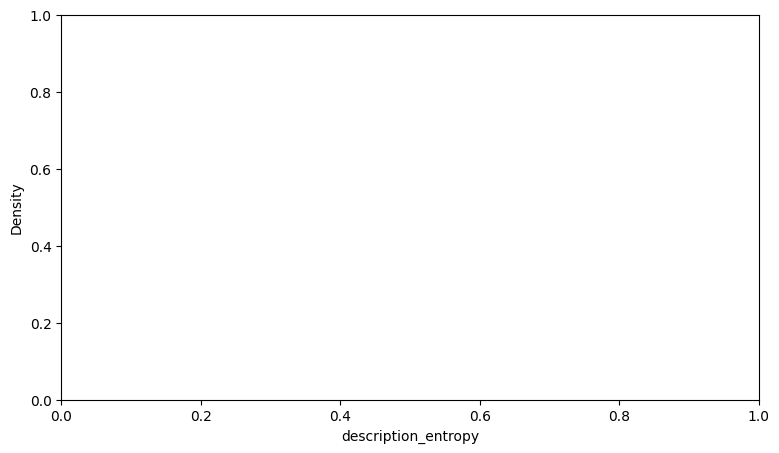

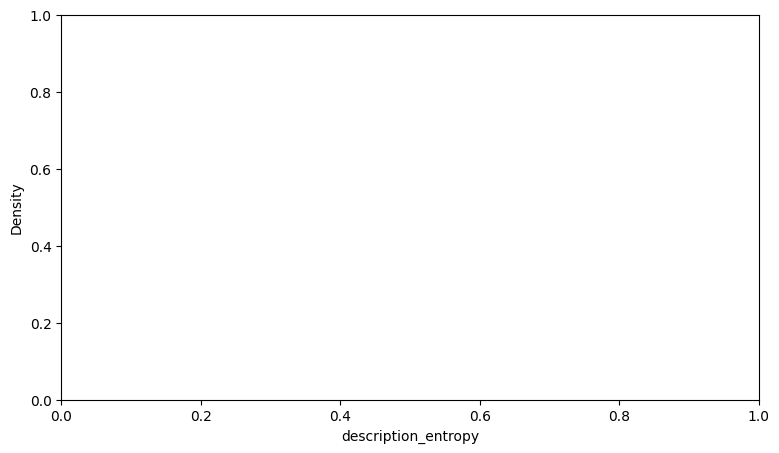

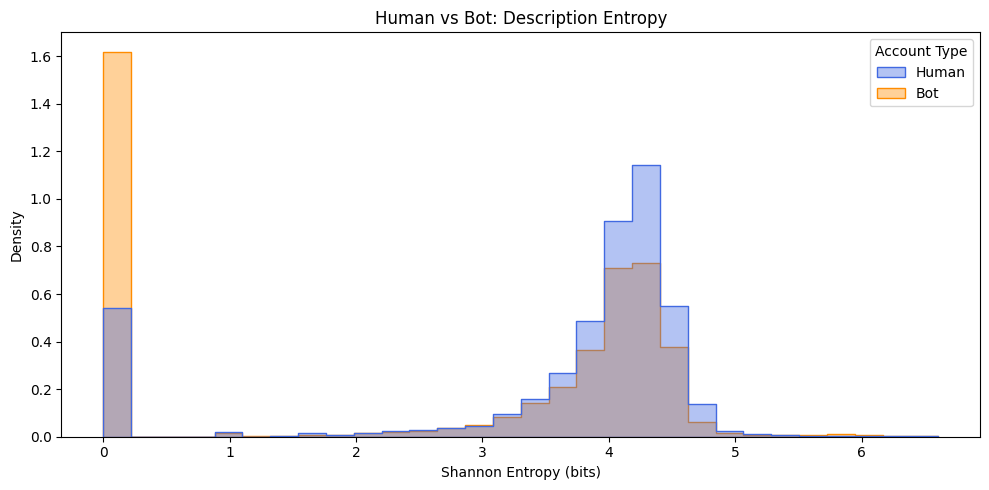

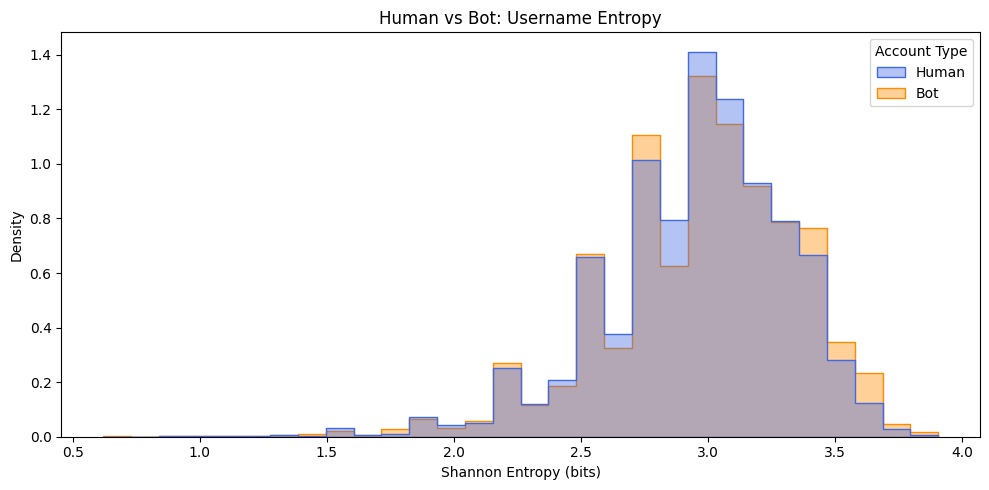

In [ ]:

# ============================================================
# FIXED ENTROPY VISUALIZATION
# ============================================================

import matplotlib.pyplot as plt
import seaborn as sns

plot_df = df.loc[df["split"] == 0].copy()

# Support both numerical and string labels
plot_df["Account Type"] = (
    plot_df["account_type"]
    .astype(str)
    .str.strip()
    .str.lower()
    .map({
        "0": "Human",
        "1": "Bot",
        "human": "Human",
        "bot": "Bot"
    })
)

print(plot_df["Account Type"].value_counts())

for feature in entropy_features:

    plt.figure(figsize=(10, 5))

    sns.histplot(
        data=plot_df,
        x=feature,
        hue="Account Type",
        hue_order=["Human", "Bot"],
        palette={
            "Human": "royalblue",
            "Bot": "darkorange"
        },
        stat="density",
        common_norm=False,
        bins=30,
        element="step",
        alpha=0.4
    )

    plt.title(
        f"Human vs Bot: {feature.replace('_', ' ').title()}"
    )

    plt.xlabel("Shannon Entropy (bits)")
    plt.ylabel("Density")
    plt.tight_layout()
    plt.show()


Percentage of missing descriptions:


,has_description
account_type,
bot,35.18
human,11.52



Entropy statistics excluding empty descriptions:


,count,mean,median,std
account_type,,,,
bot,6438,3.9857,4.1227,0.6865
human,17711,4.0297,4.1611,0.6115


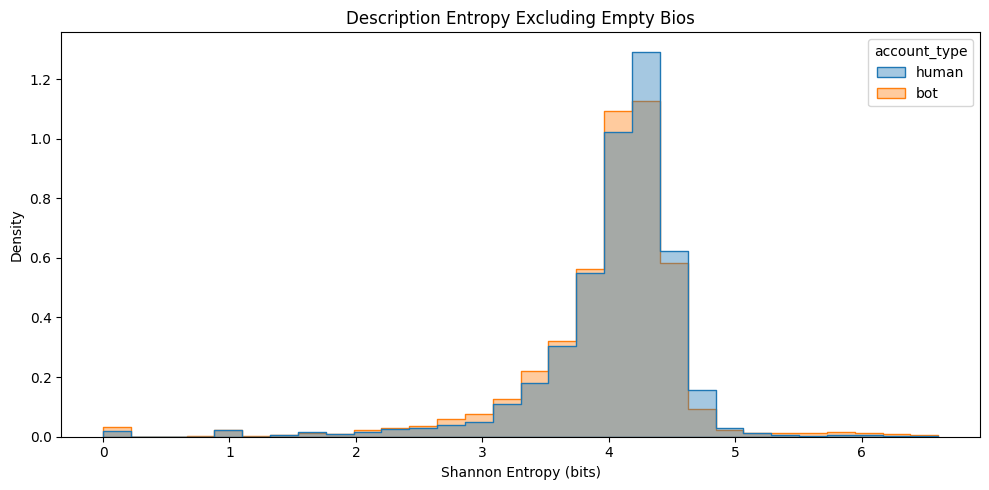

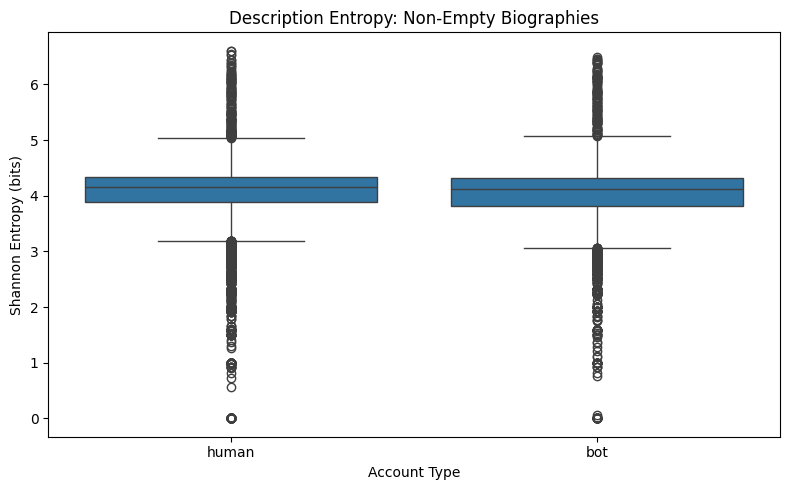

In [ ]:

# ============================================================
# ENTROPY ANALYSIS WITHOUT EMPTY DESCRIPTIONS
# ============================================================

training_df = df.loc[df["split"] == 0].copy()

training_df["has_description"] = (
    training_df["description"]
    .fillna("")
    .astype(str)
    .str.strip()
    .ne("")
)

# Percentage of missing descriptions
print("Percentage of missing descriptions:")

display(
    (
        1 - training_df.groupby(
            "account_type"
        )["has_description"].mean()
    ).mul(100).round(2)
)

# Keep only accounts with actual descriptions
non_empty_df = training_df[
    training_df["has_description"]
].copy()

print("\nEntropy statistics excluding empty descriptions:")

display(
    non_empty_df.groupby("account_type")[
        "description_entropy"
    ].agg([
        "count",
        "mean",
        "median",
        "std"
    ]).round(4)
)

# Visualize non-empty descriptions
plt.figure(figsize=(10, 5))

sns.histplot(
    data=non_empty_df,
    x="description_entropy",
    hue="account_type",
    stat="density",
    common_norm=False,
    bins=30,
    element="step",
    alpha=0.4
)

plt.title("Description Entropy Excluding Empty Bios")
plt.xlabel("Shannon Entropy (bits)")
plt.ylabel("Density")
plt.tight_layout()
plt.show()

# Boxplot
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=non_empty_df,
    x="account_type",
    y="description_entropy"
)

plt.title("Description Entropy: Non-Empty Biographies")
plt.xlabel("Account Type")
plt.ylabel("Shannon Entropy (bits)")
plt.tight_layout()
plt.show()


# NUMERICAL IMAGE FEATURE EXTRACTION

In [ ]:
import os
import cv2
import time
import numpy as np
import pandas as pd

from tqdm.auto import tqdm

image_features = [
    "image_entropy",
    "image_brightness",
    "image_contrast",
    "image_sharpness",
    "image_saturation",
    "image_edge_density"
]

def extract_image_features(relative_path):

    missing = [np.nan] * len(image_features)

    # Handle missing image paths
    if pd.isna(relative_path):
        return missing

    full_path = os.path.join(
        path, str(relative_path)
    )

    # Check whether image exists
    if not os.path.isfile(full_path):
        return missing

    # Read image
    image = cv2.imread(full_path)

    if image is None:
        return missing

    # Standardize image dimensions
    image = cv2.resize(image, (128, 128))

    # Convert to grayscale
    gray = cv2.cvtColor(
        image, cv2.COLOR_BGR2GRAY
    )

    # Convert to HSV
    hsv = cv2.cvtColor(
        image, cv2.COLOR_BGR2HSV
    )

    # --------------------------------------------------------
    # FEATURE 1: IMAGE ENTROPY
    # --------------------------------------------------------

    histogram = np.bincount(
        gray.ravel(),
        minlength=256
    ).astype(float)

    probabilities = histogram / histogram.sum()

    probabilities = probabilities[
        probabilities > 0
    ]

    image_entropy = -np.sum(
        probabilities * np.log2(probabilities)
    )

    # --------------------------------------------------------
    # FEATURE 2: BRIGHTNESS
    # --------------------------------------------------------

    brightness = np.mean(gray)

    # --------------------------------------------------------
    # FEATURE 3: CONTRAST
    # --------------------------------------------------------

    contrast = np.std(gray)

    # --------------------------------------------------------
    # FEATURE 4: SHARPNESS
    # --------------------------------------------------------

    sharpness = cv2.Laplacian(
        gray,
        cv2.CV_64F
    ).var()

    # --------------------------------------------------------
    # FEATURE 5: SATURATION
    # --------------------------------------------------------

    saturation = np.mean(hsv[:, :, 1])

    # --------------------------------------------------------
    # FEATURE 6: EDGE DENSITY
    # --------------------------------------------------------

    edges = cv2.Canny(gray, 100, 200)

    edge_density = np.mean(edges > 0)

    return [
        image_entropy,
        brightness,
        contrast,
        sharpness,
        saturation,
        edge_density
    ]


# Start timing
start_time = time.perf_counter()

tqdm.pandas()

# Extract features from all profile images
image_data = df["profile_image_path"].progress_apply(
    extract_image_features
)

# Add numerical image features to dataset
df[image_features] = pd.DataFrame(
    image_data.tolist(),
    index=df.index,
    columns=image_features
)

extraction_time = time.perf_counter() - start_time

# Identify successfully processed images
df["valid_image"] = (
    df[image_features].notna().all(axis=1)
)

print("\n========== IMAGE EXTRACTION RESULTS ==========")

print("Total accounts:", len(df))

print(
    "Successfully processed images:",
    df["valid_image"].sum()
)

print(
    "Missing or unreadable images:",
    (~df["valid_image"]).sum()
)

print(
    "Extraction time (seconds):",
    round(extraction_time, 2)
)

print("\nImage availability by split and account type:")

display(
    pd.crosstab(
        [df["split"], df["account_type"]],
        df["valid_image"]
    )
)

print("\nExtracted image features:")

display(
    df.loc[df["valid_image"], image_features]
    .head(10)
    .round(4)
)

print("\nTraining image feature statistics:")

display(
    df.loc[
        df["split"] == 0,
        image_features
    ].describe().round(4)
)

# Save extracted features to avoid repeating extraction
df[["id"] + image_features].to_csv(
    "extracted_image_features.csv",
    index=False
)

print("\nSaved extracted_image_features.csv")


  0%|          | 0/37438 [00:00<?, ?it/s]


========== IMAGE EXTRACTION RESULTS ==========
Total accounts: 37438
Successfully processed images: 24498
Missing or unreadable images: 12940
Extraction time (seconds): 123.62

Image availability by split and account type:


valid_image         False  True 
split account_type              
0     bot            1217   8715
      human          9100  10918
1     bot             146   1121
      human          1135   1341
2     bot             156   1070
      human          1186   1333


Extracted image features:


,image_entropy,image_brightness,image_contrast,image_sharpness,image_saturation,image_edge_density
1,6.9646,122.6763,31.1581,32.1830,61.9609,0.0208
3,7.5711,98.0496,50.1770,105.6266,89.1080,0.1006
4,7.2586,117.4850,50.6331,42.4861,147.4270,0.0389
5,6.9716,156.5618,33.5690,98.8283,60.4581,0.0674
6,7.3886,178.2874,51.8326,44.4678,86.3075,0.0595
9,7.4750,122.8627,51.1001,25.5074,77.8171,0.0254
10,7.1209,78.3885,51.1211,55.2753,129.6965,0.0361
11,6.6190,149.1805,88.4884,37.2600,83.0737,0.0432
12,7.6428,87.6190,74.4517,323.4514,115.7373,0.1353
14,2.9072,36.4728,79.1755,170.1562,0.0000,0.0413



Training image feature statistics:


,image_entropy,image_brightness,image_contrast,image_sharpness,image_saturation,image_edge_density
count,19633.0000,19633.0000,19633.0000,19633.0000,19633.0000,19633.0000
mean,6.7796,123.9965,56.3492,85.8138,77.0626,0.0602
std,1.3205,46.2193,16.8072,73.2503,47.5972,0.0316
min,-0.0000,0.0000,0.0000,0.0000,0.0000,0.0000
25%,6.6822,93.5369,45.5255,43.3155,44.0927,0.0383
50%,7.2467,120.7349,56.1940,68.4342,72.5850,0.0562
75%,7.5163,152.2819,67.0892,104.9227,104.2629,0.0778
max,7.9491,255.0000,120.3694,1333.3375,255.0000,0.2831



Saved extracted_image_features.csv


Training image distribution:


,count
Account Type,
Human,10918
Bot,8715



Image statistics by account type:


image_entropy                 image_brightness            \
                      mean  median     std             mean    median   
Account Type                                                            
Bot                 6.6697  7.2302  1.4840         126.4633  123.5301   
Human               6.8674  7.2581  1.1664         122.0273  118.6980   

                      image_contrast                   image_sharpness  \
                  std           mean   median      std            mean   
Account Type                                                             
Bot           47.2883        55.4408  55.5213  17.2957         87.5041   
Human         45.2537        57.0743  56.7426  16.3715         84.4645   

                               image_saturation                   \
               median      std             mean   median     std   
Account Type                                                       
Bot           68.9609  78.8574          76.2682  70.6771  47.627   
Human         68.1413  68.4195          77.6967  73.8768  47.566   

             image_edge_density                  
                           mean  median     std  
Account Type                                     
Bot                      0.0602  0.0565  0.0328  
Human                    0.0603  0.0560  0.0306

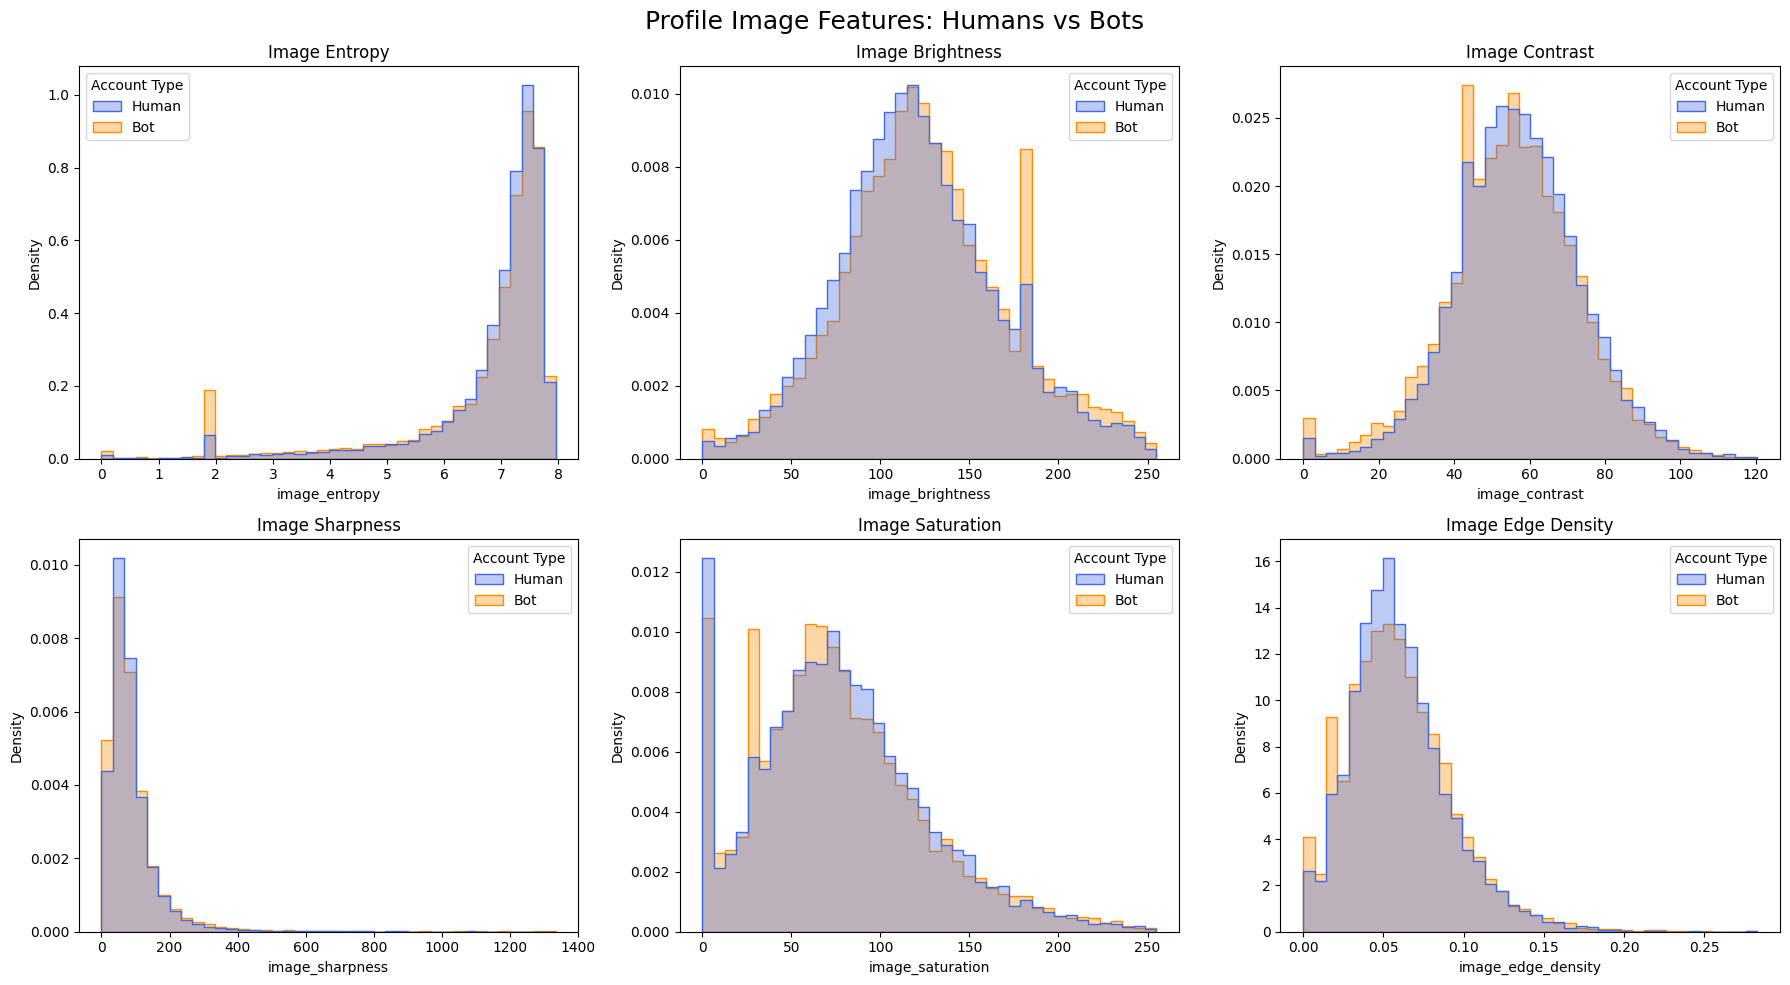

In [30]:

# ============================================================
# IMAGE FEATURE ANALYSIS: HUMAN VS BOT
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Use training data with valid images
image_analysis_df = df.loc[
    (df["split"] == 0) &
    (df["valid_image"])
].copy()

# Support both numerical and string labels
image_analysis_df["Account Type"] = (
    image_analysis_df["account_type"]
    .astype(str)
    .str.strip()
    .str.lower()
    .map({
        "0": "Human",
        "1": "Bot",
        "human": "Human",
        "bot": "Bot"
    })
)

print("Training image distribution:")

display(
    image_analysis_df["Account Type"].value_counts()
)

# Compare descriptive statistics
image_statistics = (
    image_analysis_df
    .groupby("Account Type")[image_features]
    .agg(["mean", "median", "std"])
)

print("\nImage statistics by account type:")

display(image_statistics.round(4))

# ============================================================
# VISUALIZE IMAGE FEATURE DISTRIBUTIONS
# ============================================================

fig, axes = plt.subplots(
    2, 3,
    figsize=(18, 10)
)

axes = axes.flatten()

for i, feature in enumerate(image_features):

    sns.histplot(
        data=image_analysis_df,
        x=feature,
        hue="Account Type",
        hue_order=["Human", "Bot"],
        palette={
            "Human": "royalblue",
            "Bot": "darkorange"
        },
        stat="density",
        common_norm=False,
        bins=40,
        element="step",
        alpha=0.35,
        ax=axes[i]
    )

    axes[i].set_title(
        feature.replace("_", " ").title()
    )

    axes[i].set_ylabel("Density")

plt.suptitle(
    "Profile Image Features: Humans vs Bots",
    fontsize=18
)

plt.tight_layout()
plt.show()

# Save visualization
fig.savefig(
    "image_feature_distributions.png",
    dpi=300,
    bbox_inches="tight"
)


,Feature,Human Mean,Bot Mean,Cohen's d,Absolute Effect Size
0,image_entropy,6.8674,6.6697,-0.1502,0.1502
2,image_contrast,57.0743,55.4408,-0.0973,0.0973
1,image_brightness,122.0273,126.4633,0.0961,0.0961
3,image_sharpness,84.4645,87.5041,0.0415,0.0415
4,image_saturation,77.6967,76.2682,-0.0300,0.0300
5,image_edge_density,0.0603,0.0602,-0.0037,0.0037


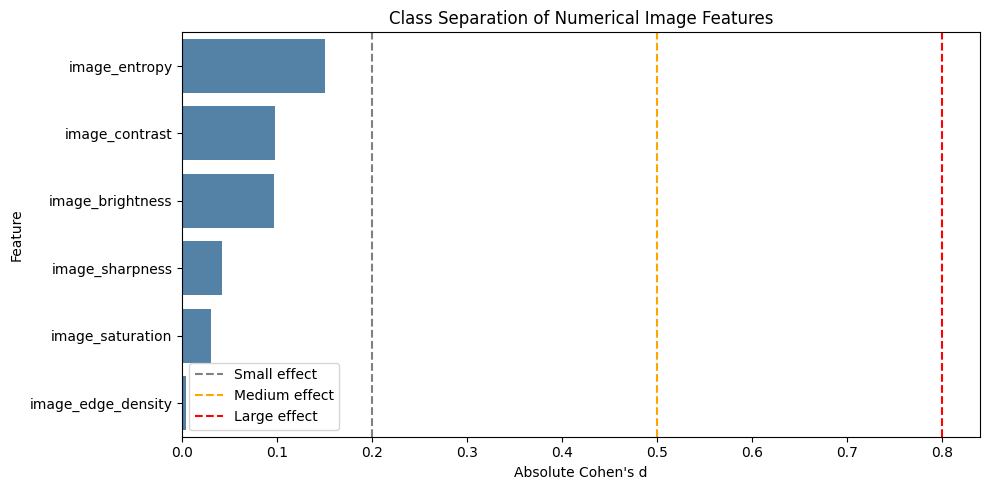

In [31]:

# ============================================================
# STANDARDIZED EFFECT SIZE FOR IMAGE FEATURES
# ============================================================

effect_sizes = []

for feature in image_features:

    human = image_analysis_df.loc[
        image_analysis_df["Account Type"] == "Human",
        feature
    ].dropna()

    bot = image_analysis_df.loc[
        image_analysis_df["Account Type"] == "Bot",
        feature
    ].dropna()

    pooled_std = np.sqrt(
        (
            (len(human) - 1) * human.var() +
            (len(bot) - 1) * bot.var()
        ) /
        (len(human) + len(bot) - 2)
    )

    d = (
        (bot.mean() - human.mean()) / pooled_std
        if pooled_std > 0 else np.nan
    )

    effect_sizes.append({
        "Feature": feature,
        "Human Mean": human.mean(),
        "Bot Mean": bot.mean(),
        "Cohen's d": d,
        "Absolute Effect Size": abs(d)
    })

effect_df = pd.DataFrame(effect_sizes)

effect_df = effect_df.sort_values(
    "Absolute Effect Size",
    ascending=False
)

display(effect_df.round(4))

plt.figure(figsize=(10, 5))

sns.barplot(
    data=effect_df,
    x="Absolute Effect Size",
    y="Feature",
    color="steelblue"
)

plt.axvline(
    0.2, linestyle="--",
    color="gray", label="Small effect"
)

plt.axvline(
    0.5, linestyle="--",
    color="orange", label="Medium effect"
)

plt.axvline(
    0.8, linestyle="--",
    color="red", label="Large effect"
)

plt.title("Class Separation of Numerical Image Features")
plt.xlabel("Absolute Cohen's d")
plt.legend()
plt.tight_layout()
plt.show()


Training accounts: 19633
Validation accounts: 2462

Training distribution:
account_type
0    10918
1     8715
Name: count, dtype: int64

Validation distribution:
account_type
0    1341
1    1121
Name: count, dtype: int64

Running E1 - Original Metadata...

Running E2 - Engineered Metadata...

Running E3 - Raw Entropy...

Running E4 - Normalized Entropy...

Running E5 - Image Features...

Running E6 - Raw Entropy + Images...

Running E7 - Normalized Entropy + Images...

========== ABLATION RESULTS ==========


,Experiment,Features,Accuracy,Bot Precision,Bot Recall,Bot F1,Training Time (s),Inference Time (s),Inference per Account (ms),F1 Change (pp)
0,E1 - Original Metadata,10,0.8578,0.8768,0.8002,0.8368,7.7845,0.0546,0.0222,-0.9436
1,E2 - Engineered Metadata,20,0.8664,0.8890,0.8073,0.8462,6.8639,0.0702,0.0285,0.0000
2,E3 - Raw Entropy,22,0.8660,0.8904,0.8046,0.8454,7.7413,0.0574,0.0233,-0.0829
3,E4 - Normalized Entropy,22,0.8623,0.8879,0.7984,0.8408,7.9510,0.0558,0.0227,-0.5419
4,E5 - Image Features,26,0.8643,0.8939,0.7966,0.8425,10.4865,0.0701,0.0285,-0.3737
5,E6 - Raw Entropy + Images,28,0.8712,0.8996,0.8073,0.8510,10.6025,0.0566,0.0230,0.4774
6,E7 - Normalized Entropy + Images,28,0.8680,0.8956,0.8037,0.8472,11.0736,0.0594,0.0241,0.1013


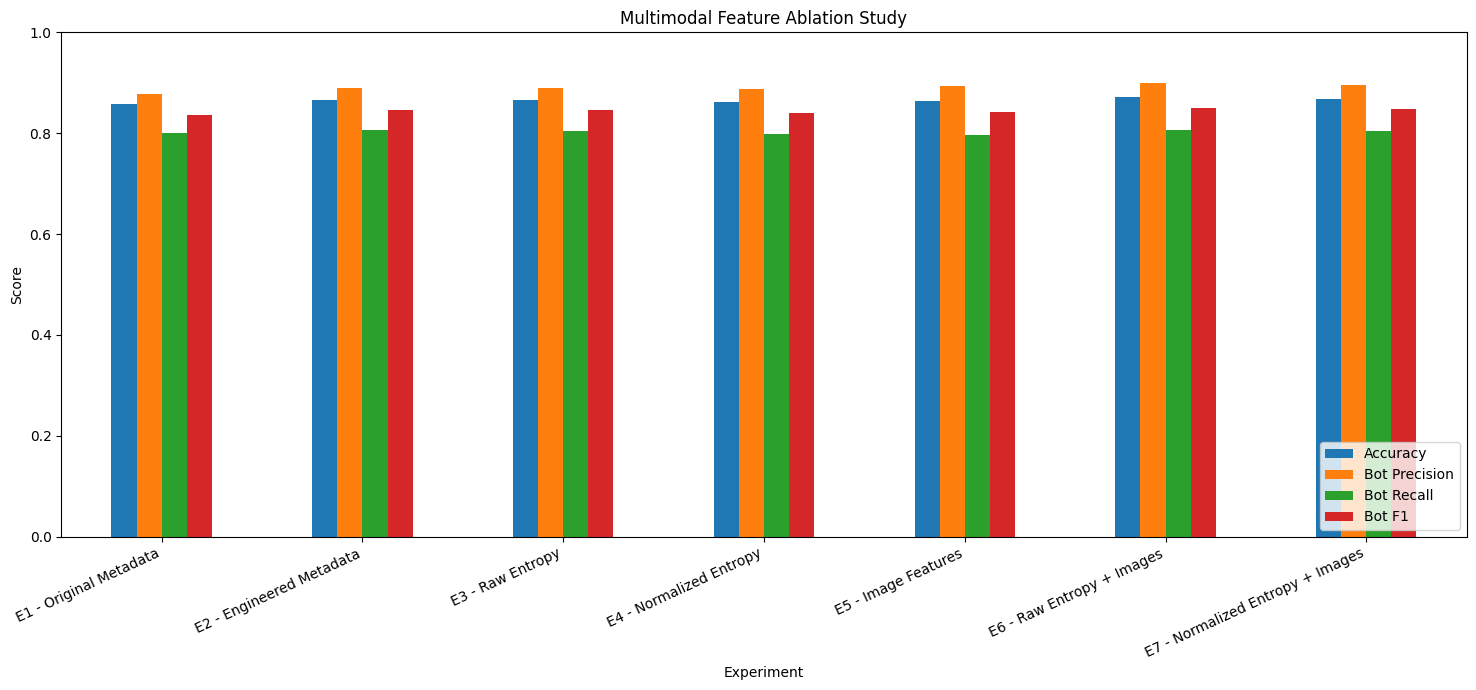

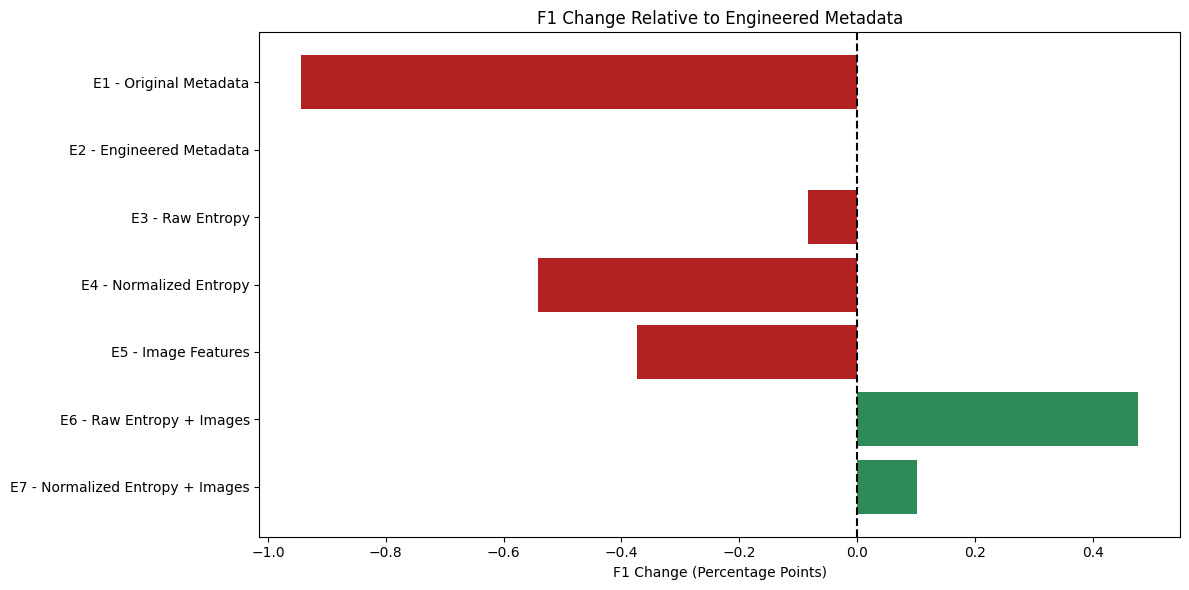


========== BEST VALIDATION MODEL ==========
Experiment: E6 - Raw Entropy + Images
Number of features: 28
Accuracy: 0.8712
Bot F1: 0.851
F1 change (pp): 0.4774


In [32]:

# ============================================================
# MULTIMODAL RANDOM FOREST ABLATION STUDY
# ============================================================

import numpy as np
import pandas as pd
import time
import matplotlib.pyplot as plt

from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

RANDOM_STATE = 42

# ============================================================
# 1. ENCODE ACCOUNT LABELS
# ============================================================

df["account_type"] = (
    df["account_type"]
    .astype(str)
    .str.strip()
    .str.lower()
    .map({
        "human": 0,
        "bot": 1,
        "0": 0,
        "1": 1
    })
)

df["split"] = pd.to_numeric(
    df["split"], errors="coerce"
)

df = df.dropna(
    subset=["account_type", "split"]
).copy()

df = df.drop_duplicates(
    subset=["id"]
).reset_index(drop=True)

df["account_type"] = df["account_type"].astype(int)

# ============================================================
# 2. ORIGINAL METADATA FEATURES
# ============================================================

original_features = [
    "default_profile",
    "default_profile_image",
    "favourites_count",
    "followers_count",
    "friends_count",
    "geo_enabled",
    "statuses_count",
    "verified",
    "average_tweets_per_day",
    "account_age_days"
]

for col in original_features:
    df[col] = pd.to_numeric(
        df[col], errors="coerce"
    )

# ============================================================
# 3. ENGINEERED METADATA FEATURES
# ============================================================

df["follower_following_ratio"] = (
    df["followers_count"] /
    (df["friends_count"] + 1)
)

df["tweets_per_follower"] = (
    df["statuses_count"] /
    (df["followers_count"] + 1)
)

df["likes_per_tweet"] = (
    df["favourites_count"] /
    (df["statuses_count"] + 1)
)

bios = df["description"].fillna("").astype(str)
usernames = df["screen_name"].fillna("").astype(str)

df["bio_length"] = bios.str.len()

df["has_bio"] = (
    bios.str.strip().ne("").astype(int)
)

df["username_length"] = usernames.str.len()

df["username_digit_count"] = usernames.apply(
    lambda s: sum(c.isdigit() for c in s)
)

df["username_digit_ratio"] = (
    df["username_digit_count"] /
    df["username_length"].clip(lower=1)
)

df["log_followers"] = np.log1p(
    df["followers_count"].clip(lower=0)
)

df["log_statuses"] = np.log1p(
    df["statuses_count"].clip(lower=0)
)

engineered_features = [
    "follower_following_ratio",
    "tweets_per_follower",
    "likes_per_tweet",
    "bio_length",
    "has_bio",
    "username_length",
    "username_digit_count",
    "username_digit_ratio",
    "log_followers",
    "log_statuses"
]

# ============================================================
# 4. NORMALIZED ENTROPY
# ============================================================

def normalized_entropy(text):

    if pd.isna(text):
        return np.nan

    text = str(text).lower().strip()

    if len(text) == 0:
        return np.nan

    if len(text) == 1:
        return 0.0

    return calculate_entropy(text) / np.log2(len(text))


df["normalized_description_entropy"] = (
    df["description"].apply(normalized_entropy)
)

df["normalized_username_entropy"] = (
    df["screen_name"].apply(normalized_entropy)
)

entropy_features = [
    "description_entropy",
    "username_entropy"
]

normalized_features = [
    "normalized_description_entropy",
    "normalized_username_entropy"
]

image_features = [
    "image_entropy",
    "image_brightness",
    "image_contrast",
    "image_sharpness",
    "image_saturation",
    "image_edge_density"
]

# ============================================================
# 5. DEFINE EXPERIMENTS
# ============================================================

metadata_features = (
    original_features + engineered_features
)

feature_sets = {

    "E1 - Original Metadata":
        original_features,

    "E2 - Engineered Metadata":
        metadata_features,

    "E3 - Raw Entropy":
        metadata_features + entropy_features,

    "E4 - Normalized Entropy":
        metadata_features + normalized_features,

    "E5 - Image Features":
        metadata_features + image_features,

    "E6 - Raw Entropy + Images":
        metadata_features +
        entropy_features +
        image_features,

    "E7 - Normalized Entropy + Images":
        metadata_features +
        normalized_features +
        image_features
}

# ============================================================
# 6. IDENTICAL ACCOUNTS FOR ALL EXPERIMENTS
# ============================================================

df["valid_image"] = (
    df[image_features].notna().all(axis=1)
)

train_mask = (
    (df["split"] == 0) &
    df["valid_image"]
)

valid_mask = (
    (df["split"] == 1) &
    df["valid_image"]
)

y_train_ablation = df.loc[
    train_mask, "account_type"
]

y_valid_ablation = df.loc[
    valid_mask, "account_type"
]

print("Training accounts:", train_mask.sum())
print("Validation accounts:", valid_mask.sum())

print("\nTraining distribution:")
print(y_train_ablation.value_counts())

print("\nValidation distribution:")
print(y_valid_ablation.value_counts())

# ============================================================
# 7. TRAIN AND EVALUATE EACH EXPERIMENT
# ============================================================

ablation_results = []
ablation_models = {}

for experiment, columns in feature_sets.items():

    print(f"\nRunning {experiment}...")

    X_train_ablation = df.loc[
        train_mask, columns
    ].replace([np.inf, -np.inf], np.nan)

    X_valid_ablation = df.loc[
        valid_mask, columns
    ].replace([np.inf, -np.inf], np.nan)

    rf_model = Pipeline([
        (
            "imputer",
            SimpleImputer(strategy="median")
        ),
        (
            "model",
            RandomForestClassifier(
                n_estimators=100,
                random_state=RANDOM_STATE,
                n_jobs=1
            )
        )
    ])

    # Measure training time
    start = time.perf_counter()

    rf_model.fit(
        X_train_ablation,
        y_train_ablation
    )

    training_time = time.perf_counter() - start

    # Warm-up prediction
    rf_model.predict(X_valid_ablation)

    # Measure inference time five times
    inference_times = []

    for _ in range(5):

        start = time.perf_counter()

        predictions = rf_model.predict(
            X_valid_ablation
        )

        inference_times.append(
            time.perf_counter() - start
        )

    inference_time = np.median(inference_times)

    ablation_results.append({

        "Experiment": experiment,

        "Features": len(columns),

        "Accuracy": accuracy_score(
            y_valid_ablation, predictions
        ),

        "Bot Precision": precision_score(
            y_valid_ablation,
            predictions,
            zero_division=0
        ),

        "Bot Recall": recall_score(
            y_valid_ablation,
            predictions,
            zero_division=0
        ),

        "Bot F1": f1_score(
            y_valid_ablation,
            predictions,
            zero_division=0
        ),

        "Training Time (s)": training_time,

        "Inference Time (s)": inference_time,

        "Inference per Account (ms)":
            inference_time * 1000 /
            len(X_valid_ablation)
    })

    ablation_models[experiment] = rf_model

# ============================================================
# 8. RESULTS
# ============================================================

ablation_df = pd.DataFrame(ablation_results)

baseline_f1 = ablation_df.loc[
    ablation_df["Experiment"] ==
    "E2 - Engineered Metadata",
    "Bot F1"
].iloc[0]

ablation_df["F1 Change (pp)"] = (
    ablation_df["Bot F1"] - baseline_f1
) * 100

print("\n========== ABLATION RESULTS ==========")

display(ablation_df.round(4))

ablation_df.to_csv(
    "multimodal_ablation_results.csv",
    index=False
)

# ============================================================
# 9. VISUALIZE CLASSIFICATION PERFORMANCE
# ============================================================

metrics = [
    "Accuracy",
    "Bot Precision",
    "Bot Recall",
    "Bot F1"
]

ax = ablation_df.set_index(
    "Experiment"
)[metrics].plot(
    kind="bar",
    figsize=(15, 7)
)

plt.title("Multimodal Feature Ablation Study")
plt.ylabel("Score")
plt.xlabel("Experiment")
plt.ylim(0, 1)
plt.xticks(rotation=25, ha="right")
plt.legend(loc="lower right")
plt.tight_layout()

plt.savefig(
    "ablation_performance.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# ============================================================
# 10. F1 IMPROVEMENT OVER ENGINEERED METADATA
# ============================================================

plt.figure(figsize=(12, 6))

changes = ablation_df["F1 Change (pp)"]

plt.barh(
    ablation_df["Experiment"],
    changes,
    color=[
        "seagreen" if x > 0 else
        "firebrick" if x < 0 else
        "gray"
        for x in changes
    ]
)

plt.axvline(0, color="black", linestyle="--")

plt.title("F1 Change Relative to Engineered Metadata")
plt.xlabel("F1 Change (Percentage Points)")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

# ============================================================
# 11. SELECT BEST VALIDATION MODEL
# ============================================================

best_row = ablation_df.loc[
    ablation_df["Bot F1"].idxmax()
]

best_experiment = best_row["Experiment"]

best_ablation_model = ablation_models[
    best_experiment
]

best_ablation_features = feature_sets[
    best_experiment
]

print("\n========== BEST VALIDATION MODEL ==========")

print("Experiment:", best_experiment)
print("Number of features:", best_row["Features"])
print("Accuracy:", round(best_row["Accuracy"], 4))
print("Bot F1:", round(best_row["Bot F1"], 4))
print("F1 change (pp):", round(best_row["F1 Change (pp)"], 4))


# METADATA VS ENTROPY VS IMAGE FEATURES

In [29]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

RANDOM_STATE = 42

# Existing 20 features
baseline_features = (
    original_features + engineered_features
)

# Define feature combinations
feature_sets = {

    "Baseline (20)":
        baseline_features,

    "Metadata + Entropy (22)":
        baseline_features + entropy_features,

    "Metadata + Images (26)":
        baseline_features + image_features,

    "Combined (28)":
        baseline_features
        + entropy_features
        + image_features
}

# ============================================================
# USE IDENTICAL ACCOUNTS FOR ALL EXPERIMENTS
# ============================================================

eligible = df["valid_image"]

train_mask = (
    (df["split"] == 0) & eligible
)

valid_mask = (
    (df["split"] == 1) & eligible
)

y_train_ablation = df.loc[
    train_mask, "account_type"
]

y_valid_ablation = df.loc[
    valid_mask, "account_type"
]

print("Training accounts:", train_mask.sum())
print("Validation accounts:", valid_mask.sum())

# Store results and trained models
ablation_results = []
ablation_models = {}

# ============================================================
# TRAIN RANDOM FOREST FOR EACH FEATURE SET
# ============================================================

for experiment, columns in feature_sets.items():

    print("\nRunning:", experiment)

    X_train_ablation = df.loc[
        train_mask, columns
    ].replace(
        [np.inf, -np.inf], np.nan
    )

    X_valid_ablation = df.loc[
        valid_mask, columns
    ].replace(
        [np.inf, -np.inf], np.nan
    )

    # Same model configuration for all experiments
    rf_model = Pipeline([
        (
            "imputer",
            SimpleImputer(strategy="median")
        ),
        (
            "model",
            RandomForestClassifier(
                n_estimators=100,
                random_state=RANDOM_STATE,
                n_jobs=1
            )
        )
    ])

    # Measure training time
    start = time.perf_counter()

    rf_model.fit(
        X_train_ablation,
        y_train_ablation
    )

    training_time = time.perf_counter() - start

    # Warm-up prediction
    rf_model.predict(X_valid_ablation)

    # Measure inference time repeatedly
    inference_times = []

    for _ in range(5):

        start = time.perf_counter()

        predictions = rf_model.predict(
            X_valid_ablation
        )

        inference_times.append(
            time.perf_counter() - start
        )

    inference_time = np.median(inference_times)

    # Store evaluation results
    ablation_results.append({

        "Experiment": experiment,

        "Features": len(columns),

        "Accuracy": accuracy_score(
            y_valid_ablation,
            predictions
        ),

        "Bot Precision": precision_score(
            y_valid_ablation,
            predictions,
            zero_division=0
        ),

        "Bot Recall": recall_score(
            y_valid_ablation,
            predictions,
            zero_division=0
        ),

        "Bot F1": f1_score(
            y_valid_ablation,
            predictions,
            zero_division=0
        ),

        "Training Time (s)": training_time,

        "Inference Time (s)": inference_time
    })

    ablation_models[experiment] = rf_model

# ============================================================
# DISPLAY RESULTS
# ============================================================

ablation_df = pd.DataFrame(ablation_results)

baseline_f1 = ablation_df.loc[
    ablation_df["Experiment"] == "Baseline (20)",
    "Bot F1"
].iloc[0]

ablation_df["F1 Change (pp)"] = (
    (ablation_df["Bot F1"] - baseline_f1) * 100
)

print("\n========== ABLATION RESULTS ==========")

display(ablation_df.round(4))

# ============================================================
# VISUALIZE PERFORMANCE
# ============================================================

plot_results = ablation_df.melt(
    id_vars="Experiment",
    value_vars=[
        "Accuracy",
        "Bot Precision",
        "Bot Recall",
        "Bot F1"
    ],
    var_name="Metric",
    value_name="Score"
)

plt.figure(figsize=(13, 6))

sns.barplot(
    data=plot_results,
    x="Experiment",
    y="Score",
    hue="Metric"
)

plt.title("Impact of Textual and Visual Features")
plt.ylabel("Classification Score")
plt.xlabel("Feature Combination")
plt.ylim(0, 1)
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

# ============================================================
# SELECT BEST VALIDATION FEATURE SET
# ============================================================

best_row = ablation_df.loc[
    ablation_df["Bot F1"].idxmax()
]

best_experiment = best_row["Experiment"]

print("\nBest feature combination:")
print(best_experiment)

print(
    "Validation Bot F1:",
    round(best_row["Bot F1"], 4)
)

print(
    "F1 change from baseline (percentage points):",
    round(best_row["F1 Change (pp)"], 4)
)

# Save results
ablation_df.to_csv(
    "multimodal_ablation_results.csv",
    index=False
)

print("\nExperiment completed successfully!")


Training accounts: 19633
Validation accounts: 2462

Running: Baseline (20)


KeyError: "['follower_following_ratio', 'tweets_per_follower', 'likes_per_tweet', 'bio_length', 'has_bio', 'username_length', 'username_digit_count', 'username_digit_ratio', 'log_followers', 'log_statuses'] not in index"

# extra

In [ ]:
import pandas as pd
import kagglehub
import os

# Load the cached dataset
path = kagglehub.dataset_download(
    "danieltreiman/twitter-human-bots-dataset"
)

df = pd.read_csv(
    os.path.join(path, "twitter_human_bots_dataset.csv")
)

# Check split values
print("Unique split values:")
print(df["split"].unique())

print("\nNumber of accounts in each split:")
print(df["split"].value_counts(dropna=False))

print("\nBot and human counts in each split:")
print(pd.crosstab(df["split"], df["account_type"]))

Using Colab cache for faster access to the 'twitter-human-bots-dataset' dataset.
Unique split values:
[0 1 2]

Number of accounts in each split:
split
0    29950
2     3745
1     3743
Name: count, dtype: int64

Bot and human counts in each split:
account_type   bot  human
split                    
0             9932  20018
1             1267   2476
2             1226   2519


In [ ]:
import os

print("Dataset folder:", path)

print("\nTop-level files and folders:")
print(os.listdir(path)[:30])

print("\nNon-null profile image paths:")
print(df["profile_image_path"].notna().sum())

print("\nNon-null background image paths:")
print(df["profile_background_image_path"].notna().sum())

print("\nExample profile image paths:")
print(df["profile_image_path"].dropna().head(5).tolist())

# Check whether referenced images actually exist
sample_paths = df["profile_image_path"].dropna().head(10)

for relative_path in sample_paths:
    full_path = os.path.join(path, str(relative_path))
    print(os.path.isfile(full_path), full_path)

Dataset folder: /kaggle/input/twitter-human-bots-dataset

Top-level files and folders:
['twitter_human_bots_dataset.csv', 'profile_images', 'profile_background_images']

Non-null profile image paths:
24500

Non-null background image paths:
24500

Example profile image paths:
['profile_images/4691ae58668d932bb7e7af22141aecfc8f159764.jpg', 'profile_images/d1da9220e4aa376dff03b6f127651713b71fbc4e.jpg', 'profile_images/c65bf625b066ef5f29e14cfcf1ee91fea680df47.jpg', 'profile_images/848c190606cd415153938b4e45ec83fef4544fd0.jpg', 'profile_images/4a020d1683687ab89250f76b06895ed06ac7af74.jpg']
True /kaggle/input/twitter-human-bots-dataset/profile_images/4691ae58668d932bb7e7af22141aecfc8f159764.jpg
True /kaggle/input/twitter-human-bots-dataset/profile_images/d1da9220e4aa376dff03b6f127651713b71fbc4e.jpg
True /kaggle/input/twitter-human-bots-dataset/profile_images/c65bf625b066ef5f29e14cfcf1ee91fea680df47.jpg
True /kaggle/input/twitter-human-bots-dataset/profile_images/848c190606cd415153938b4e45ec8